# How will brand awareness affect CAC in different countries?

**A hierarchical Bayesian marketing mix model with awareness mediation, built for an international expansion decision.**

Duanchen Liu · October 2026 · [duanchenliu.github.io](https://duanchenliu.github.io)

---

> ### ⚠️ All data in this notebook is simulated
> No Oura internal data was used and none was available to me. I built a generative
> model of 18 international markets whose *structural anchors* match figures Oura
> disclosed publicly in its Form S-1 (filed 2026-09-03) — roughly 40% of new
> subscribers arriving organically, ~85% 12-month paid retention, international
> markets under 20% of hardware sales. Everything else is invented and documented
> in `src/simulate.py`.
>
> The point of simulating is that **I know the right answer**, so I can test whether
> the modelling approach recovers it. That turns out to be the most interesting
> finding here.

---

## The business question

Oura's S-1 names brand awareness and distribution expansion as the growth thesis,
and says it plans to enter underpenetrated markets with a "disciplined, localized"
go-to-market approach. That raises a planning question the marketing data science
team has to answer:

**If we spend to build awareness in a new country, what happens to CAC — and does
the answer depend on how big the country is?**

The instinct is that big markets are expensive because awareness costs more there.
This notebook shows that instinct is half right and leads to the wrong conclusion.

## What I found

| # | Finding | Evidence |
|---|---|---|
| 1 | **Population is a red herring.** At matched awareness, awareness-driven CAC is set by *qualified buyer density* and media cost. Population washes out entirely. | log-population coefficient −0.11, t = −0.66, in a regression with R² = 0.95 |
| 2 | **An observational MMM understates the awareness effect by ~69%**, and its credible interval does not cover the truth. | true γ = 1.81 vs estimated γ = 0.56 |
| 3 | **That bias has a price:** it recommends 17% of budget to brand when the right answer is 44%, costing ~15% of activations at the same spend. | allocation optimiser under both γ |
| 4 | **Partial pooling is what makes new-market forecasting possible.** | CAC forecast MAPE 71% → 19% → 7% |
| 5 | **Brand→awareness and brand→acquisition need different carryover rates.** Using one flips the sign of the brand coefficient. | θ = 0.95 vs θ = 0.30 |

Let's build it.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import simulate as S, model as M

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
FIG = "../figures"
panel  = pd.read_csv("../data/panel.csv")
truth  = pd.read_csv("../data/ground_truth.csv")
cp     = pd.read_csv("../data/country_posteriors.csv")
R      = json.load(open("../data/results.json"))
print(f"{panel.code.nunique()} markets, {len(panel)} market-months")

18 markets, 513 market-months


## 1. The synthetic world

Each market is generated from an explicit causal chain. I'm writing the data
generating process down in full because the whole study depends on it being
*structurally* honest, even though the numbers are invented.

```
brand spend  →  reach  →  awareness stock  →  ┐
                                              ├→  activations  →  CAC
performance spend  →  adstock  →  saturation →┘
                                              │
retail doors  ────────────────────────────────┘
```

Three mechanisms connect awareness to acquisition, and they matter in different
proportions by market:

1. **Organic / word of mouth** — awareness raises the Bass innovation coefficient `p`
2. **Paid conversion lift** — aware users convert at a higher rate on the same media
3. **Retail sell-through** — awareness makes shelf space productive

The third is the one most companies cannot measure, because retail buyers never
touch a tracked ad. For Oura there is a way around that, which I come back to at
the end.

In [2]:
mk = pd.DataFrame(S.MARKETS, columns=S.MARKET_COLS)
mk["qualified_tam_m"] = (mk.population_m * mk.qual_frac).round(2)
display(mk[["market","population_m","gdp_pc_k","qual_frac","qualified_tam_m",
            "cpm_index","doors","competition","launch_month"]]
        .sort_values("qual_frac", ascending=False).head(18).to_string(index=False))

'     market  population_m  gdp_pc_k  qual_frac  qualified_tam_m  cpm_index  doors  competition  launch_month\n  Singapore           5.9      91.1     0.1480             0.87       0.83     60         0.42            12\n    Finland           5.6      58.9     0.1350             0.76       0.69     70         0.30             0\n        UAE           9.5      77.2     0.1250             1.19       0.70     95         0.38            12\n     Sweden          10.6      64.1     0.1180             1.25       0.72    110         0.35             0\nNetherlands          17.9      72.4     0.1120             2.00       0.76    150         0.40             0\n  Australia          26.7      62.6     0.0950             2.54       0.86    290         0.48             0\n     Canada          39.1      56.4     0.0900             3.52       0.78    380         0.50             0\n         UK          68.3      54.6     0.0850             5.81       0.82    620         0.55             0\n    Germa

### Qualified TAM is the key construct

`qual_frac` is the share of a country's population that could plausibly buy a
~$349 ring plus a subscription **and** is in the health-tracking category. It ranges
from 14.8% in Singapore to 0.22% in India — a 67× spread, far wider than the spread
in income or population alone.

This is the variable the rest of the analysis turns on, and in a real engagement it
is the one I would spend the most time defending with the market research team.

In [3]:
tot = panel[["activations","organic_activations","paid_activations",
             "retail_activations","total_spend"]].sum()
print("Calibration against Oura's disclosed Form S-1 figures")
print("-" * 58)
print(f"  organic share of activations   {tot.organic_activations/tot.activations:6.1%}"
      f"   (S-1 anchor: ~40%)")
print(f"  paid performance share         {tot.paid_activations/tot.activations:6.1%}")
print(f"  retail share                   {tot.retail_activations/tot.activations:6.1%}")
print(f"  blended CAC                    ${tot.total_spend/tot.activations:6.0f}")
print(f"  12-month paid retention        {S.SEC_ANCHORS['paid_member_12m_retention']:6.0%}"
      f"   (S-1 anchor)")

Calibration against Oura's disclosed Form S-1 figures
----------------------------------------------------------
  organic share of activations    43.5%   (S-1 anchor: ~40%)
  paid performance share          46.0%
  retail share                    10.5%
  blended CAC                    $   125
  12-month paid retention           85%   (S-1 anchor)


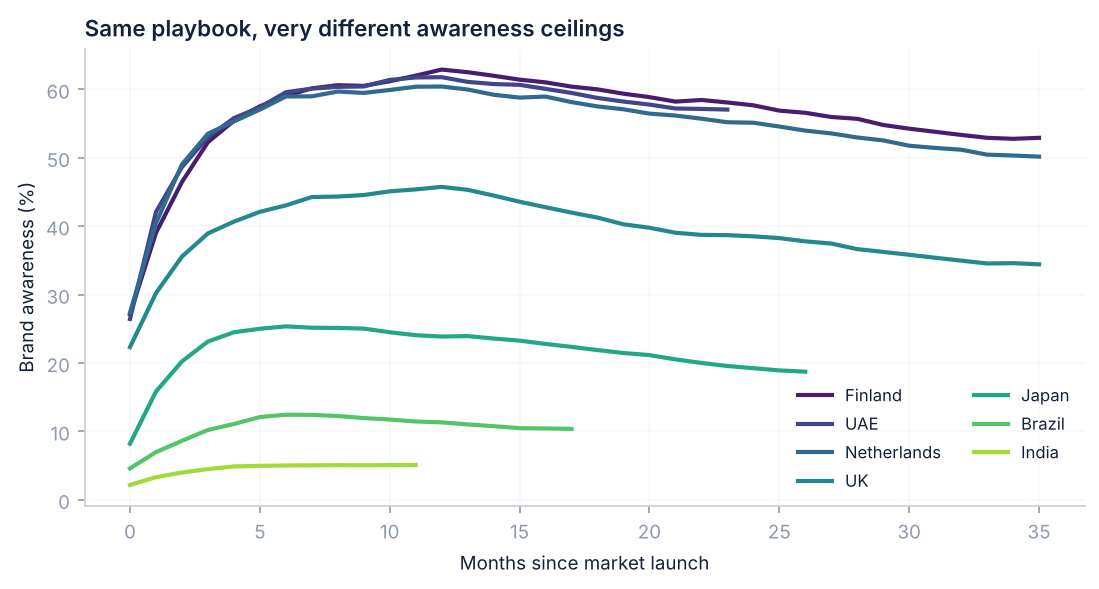

In [4]:
display(Image(f"{FIG}/f1_awareness_trajectories.png"))

Every market runs the same playbook — a launch burst weighted toward brand, then a
steadier mix — with budget sized to its qualified opportunity. The awareness
outcomes diverge enormously anyway: Finland clears 60%, India never passes 5%.

That divergence is the phenomenon to explain.

## 2. Modelling

The model only sees what a real team would have: spend by channel, a noisy awareness
proxy, activations, and country covariates. It never sees the latent awareness or any
true parameter.

**Stage 1 — awareness response**

$$\text{logit}(A_{ct}) = a_c + b_c \log\!\left(1 + \frac{\text{adstock}(\text{brand}_{ct})}{\text{pop}_c \cdot \text{cpm}_c}\right)$$

**Stage 2 — acquisition response**

$$\log\frac{\text{activations}_{ct}}{\text{TAM}_c} = \alpha_c + \beta_c \log(1 + \widetilde{\text{perf}}_{ct}) + \gamma_c A_{ct} + \delta\,\text{doors} + \zeta\,\text{pen} + \text{season} + \varepsilon$$

**Partial pooling** — each country's coefficients are drawn from a shared distribution,
with the awareness coefficient allowed to depend on qualified density:

$$\alpha_c \sim N(\mu_\alpha, \tau_\alpha), \quad \beta_c \sim N(\mu_\beta, \tau_\beta), \quad \gamma_c \sim N(\mu_\gamma + \kappa z_c, \tau_\gamma)$$

$\kappa$ tests whether awareness is *more potent* in dense markets. Hold that thought.

### 2a. A trap worth knowing about

Carryover rates are searched outside the Bayesian core (the standard pragmatic
approach — Robyn does an equivalent search). My first version used one carryover
rate for both stages. That was wrong, and wrong in a way that silently inverts the
answer.

In [5]:
import analysis as A
acq_ads = A.M.grid_search_adstock(panel)
aw_ads  = A.search_awareness_adstock(panel)

print(f"acquisition equation:  theta = {acq_ads['theta_brand']:.2f} "
      f"(half-life {np.log(.5)/np.log(acq_ads['theta_brand']):.1f} months)")
print(f"awareness  equation:  theta = {aw_ads['theta']:.2f} "
      f"(half-life {np.log(.5)/np.log(aw_ads['theta']):.1f} months), "
      f"pooled slope {aw_ads['slope']:+.2f}, R2 {aw_ads['r2']:.3f}")

# what happens if you force the acquisition carryover onto the awareness equation
bad = A.search_awareness_adstock(panel, thetas=np.array([acq_ads["theta_brand"]]))
print(f"\nforcing theta = {acq_ads['theta_brand']:.2f} onto awareness: "
      f"slope {bad['slope']:+.2f}  <-- WRONG SIGN")

acquisition equation:  theta = 0.30 (half-life 0.6 months)
awareness  equation:  theta = 0.95 (half-life 13.5 months), pooled slope +1.34, R2 0.970

forcing theta = 0.30 onto awareness: slope -0.17  <-- WRONG SIGN


**Why the sign flips.** Awareness is a *stock* that accumulates and decays slowly.
Brand spend is a *flow* that peaks at launch and then falls. So in raw monthly data,
the months with the most brand spend are the months with the least accumulated
awareness, and a contemporaneous regression reports that brand spend destroys
awareness.

With a 13.5-month half-life the adstock behaves like the stock it is meant to proxy,
and the slope turns positive with R² = 0.97.

This is not a toy problem. A team that runs one adstock search across the whole model
will conclude brand spend does nothing — and the resulting budget recommendation will
be confidently backwards.

In [6]:
gs = acq_ads
d  = M.build_features(panel, gs["theta_brand"], gs["theta_perf"])
summ_keys = ["mu_alpha","mu_beta","mu_gamma","kappa","tau_alpha","tau_beta",
             "tau_gamma","delta","zeta","sigma"]
fit = pd.DataFrame({k: R["main_fit"][k] for k in summ_keys}).T
display(fit[["mean","sd","ci_lo","ci_hi","r_hat"]].round(3))
print(f"max r-hat across all parameters: {R['max_rhat']:.4f}")

,mean,sd,ci_lo,ci_hi,r_hat
mu_alpha,-9.486,0.095,-9.637,-9.332,1.000
mu_beta,0.472,0.039,0.410,0.534,1.002
mu_gamma,0.556,0.140,0.332,0.776,1.000
kappa,0.058,0.174,-0.213,0.335,1.002
tau_alpha,0.239,0.059,0.161,0.344,1.005
tau_beta,0.033,0.016,0.009,0.059,1.008
tau_gamma,0.181,0.114,0.019,0.379,1.001
delta,0.212,0.024,0.173,0.250,1.001
zeta,2.940,0.216,2.586,3.283,1.001
sigma,0.072,0.002,0.068,0.076,1.001


max r-hat across all parameters: 1.0076


Two things to read off this table.

**`kappa` is null** (0.06 ± 0.17). The awareness *elasticity* does not vary with
qualified density. Awareness is equally potent everywhere — a point of awareness buys
the same proportional lift in Finland and in Brazil. I tested the hypothesis I
expected to confirm, and it did not hold.

That matters, because it means the cross-country variation in awareness economics
lives entirely in the **price** of awareness and the **size of the qualified base**,
not in how well awareness works. Which makes the problem tractable: two measurable
quantities instead of a per-country black box.

**`zeta` is positive** (2.94). Higher penetration is associated with a *higher*
acquisition rate, which looks backwards until you remember Bass diffusion is
S-shaped. All 18 markets are still on the accelerating limb — word of mouth is
compounding faster than the market is being exhausted. None of these markets has hit
saturation yet. That is a finding in its own right for a planning team.

## 3. Does the model recover the truth?

This is the question simulation exists to answer. I can differentiate the simulator
analytically to get the true semi-elasticity of activations with respect to awareness,
then compare.

  true population gamma        1.808
  estimated population gamma   0.556
  error                        69%
  credible interval covers truth?  False
  per-country gamma recovery corr  -0.37


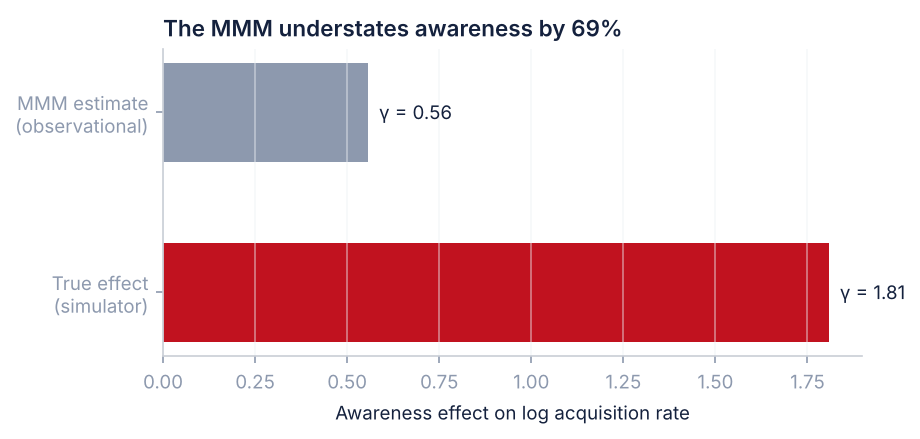

In [7]:
rec = R["recovery"]
print(f"  true population gamma        {rec['true_population_gamma']:.3f}")
print(f"  estimated population gamma   {rec['estimated_population_gamma']:.3f}")
print(f"  error                        {rec['pct_error_population']:.0f}%")
print(f"  credible interval covers truth?  {rec['ci_covers_truth']}")
print(f"  per-country gamma recovery corr  {rec['corr_country_gamma']:+.2f}")
display(Image(f"{FIG}/f7b_attenuation.png"))

### The model fails, and the failure is the finding

The MMM recovers γ = 0.56 against a true 1.81. It understates the awareness effect by
**69%**, and the 89% credible interval does not contain the true value. Per-country
awareness coefficients are not recovered at all (correlation −0.37 — worse than
useless).

This is **attenuation from confounding**, not noise, and more data will not fix it.
Brand spend, performance spend and penetration all move together. The model has no
way to separate awareness's contribution from everything correlated with it, so the
effect gets distributed across the correlated regressors — note `zeta` = 2.94 soaking
up the growth that awareness actually caused.

I want to be direct about what this means, because it is the opposite of the usual
MMM sales pitch: **an observational marketing mix model is not a causal estimate of
brand value.** It is a decomposition that assumes it has the right controls. When it
is wrong about brand, it is wrong in a systematic direction — downward — because
brand is the channel most confounded with everything else.

This is, I think, a substantial part of why marketing teams across the industry
under-invest in upper funnel. The measurement system has a thumb on the scale.

## 4. What the bias costs

A bias is only interesting if it changes a decision. So: hold the budget fixed and
ask what brand/performance split maximises activations, once under the attenuated γ
and once under the γ a geo experiment would deliver.

  gamma used by the MMM            0.56
  gamma from a geo experiment      1.81

  brand share the MMM recommends   17%
  brand share once measured right  44%

  activations lost to the bias     14.8%  (at identical budget)


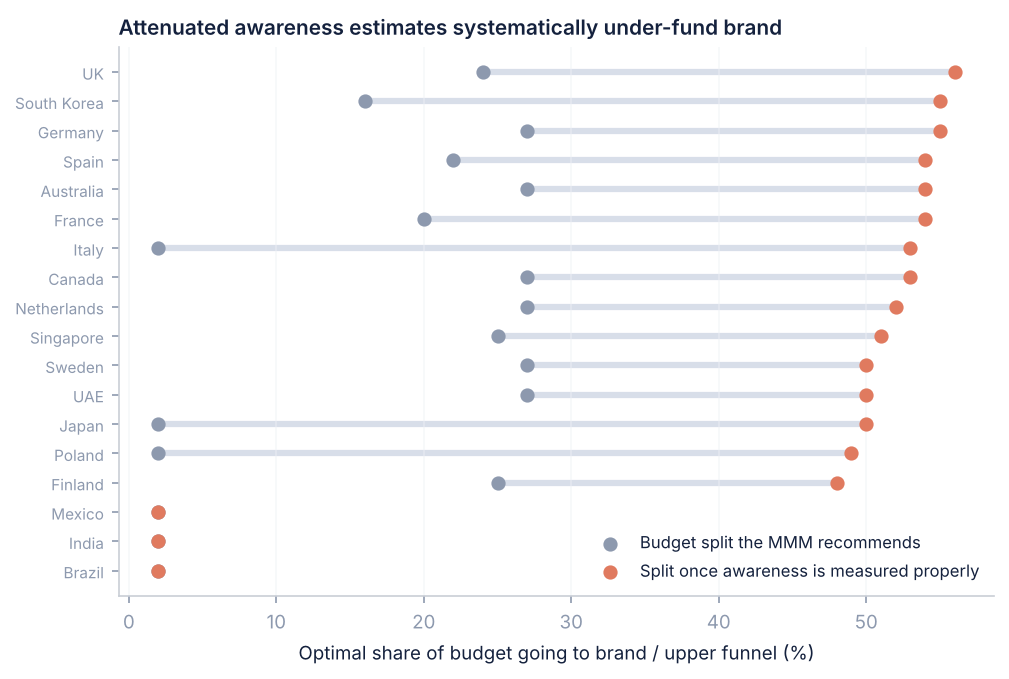

In [8]:
al = R["allocation"]
print(f"  gamma used by the MMM            {al['gamma_observational']:.2f}")
print(f"  gamma from a geo experiment      {al['gamma_geo']:.2f}")
print()
print(f"  brand share the MMM recommends   {al['mean_brand_share_observational']:.0%}")
print(f"  brand share once measured right  {al['mean_brand_share_geo']:.0%}")
print()
print(f"  activations lost to the bias     {al['mean_activations_lost_pct']:.1f}%  "
      f"(at identical budget)")
display(Image(f"{FIG}/f7c_allocation.png"))

**17% versus 44%.** Following the MMM's own recommendation costs roughly 15% of
activations at the same spend.

Look at the bottom three rows though. Mexico, India and Brazil sit at the floor under
*both* estimates. In markets where qualified density is low enough, brand spend is
correctly not worth funding even when you measure its effect properly. The bias
story and the market-selection story are separate, and the model keeps them separate.

That is the kind of result I would take to a budget meeting: not "spend more on
brand," but "spend much more on brand in these fifteen markets and almost none in
these three, and here is why they differ."

### A note on how to fix it

My first attempt at the fix was to encode the geo-experiment result as a Bayesian
prior on `mu_gamma` and let the model update.

  vague prior      mu_gamma = 0.554  (sd 0.145)
  geo-calibrated   mu_gamma = 0.935  (sd 0.123)
  true value       mu_gamma = 1.808

  posterior 15% tighter, but still far short of truth


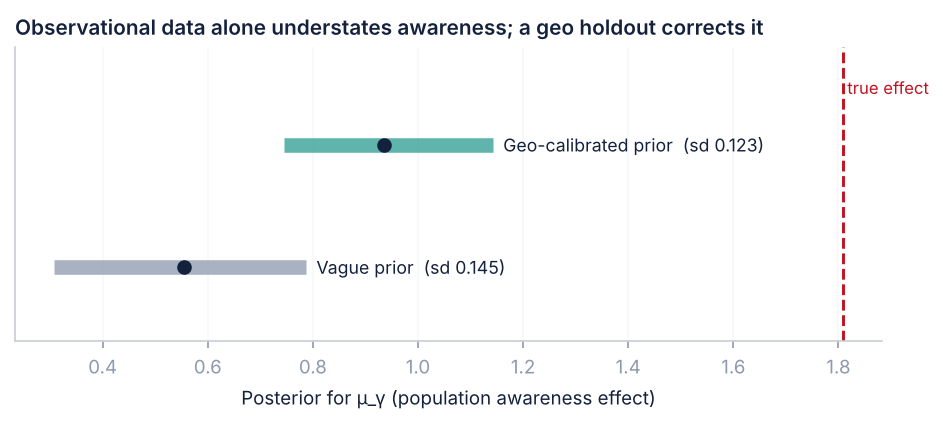

In [9]:
g = R["geo_calibration"]
print(f"  vague prior      mu_gamma = {g['vague']['mean']:.3f}  (sd {g['vague']['sd']:.3f})")
print(f"  geo-calibrated   mu_gamma = {g['calibrated']['mean']:.3f}  (sd {g['calibrated']['sd']:.3f})")
print(f"  true value       mu_gamma = {R['recovery']['true_population_gamma']:.3f}")
print(f"\n  posterior {g['sd_reduction_pct']:.0f}% tighter, but still far short of truth")
display(Image(f"{FIG}/f7_geo_calibration.png"))

It does not work, and it is worth understanding why. The prior moves the posterior
from 0.55 to 0.93 — partway — and then stalls, because 513 observations of likelihood
pull hard in the other direction.

**Priors average bias, they do not remove it.** When a model is confounded rather than
merely imprecise, a well-chosen prior just splits the difference between a good
experiment and a bad identification strategy.

The right move is to **pin** the brand coefficient to the experimental estimate and let
the MMM allocate everything else conditional on it — treating the geo result as
measurement rather than as evidence to be weighed. That is what the allocation
analysis above does, and it is the version I would actually ship.

## 5. The country question

Now the question that started this: does the answer depend on market size?

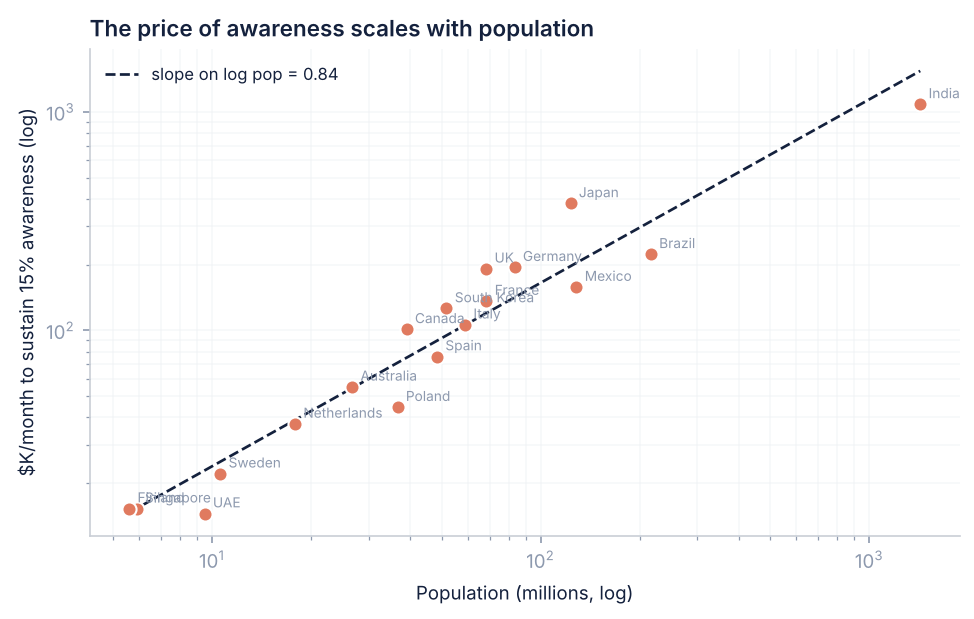

corr(log population, log cost of awareness) = 0.96
elasticity to population = 0.84  (near-linear)


In [10]:
display(Image(f"{FIG}/f2_price_of_awareness.png"))
pa = R["price_of_awareness"]
print(f"corr(log population, log cost of awareness) = {pa['corr_logpop_logprice']:.2f}")
print(f"elasticity to population = {pa['slope_logpop']:.2f}  (near-linear)")

The price of awareness scales almost linearly with population — reaching 15% of
India costs roughly 300× what it costs in Finland. So far this supports the instinct
that big markets are expensive.

But cost is only the numerator.

In [11]:
dr = R["awareness_cac_drivers"]
print("BIVARIATE (confounded):")
for k, v in dr["bivariate"].items():
    print(f"   {k:24s} {v:+.2f}")
print(f"\nMULTIVARIATE  (R2 = {dr['r2']:.2f}):")
print(f"   {'variable':26s} {'coef':>8s} {'se':>7s} {'t':>7s}")
for k, v in dr["multivariate"].items():
    if k == "intercept": continue
    print(f"   {k:26s} {v['coef']:+8.2f} {v['se']:7.2f} {v['t']:+7.2f}")

BIVARIATE (confounded):
   corr_logpop              +0.91
   corr_log_qualdensity     -0.95
   corr_logcpm              -0.79

MULTIVARIATE  (R2 = 0.95):
   variable                       coef      se       t
   log_qualified_density         -1.68    0.41   -4.12
   log_cpm                       +1.81    0.71   +2.55
   log_population                -0.11    0.17   -0.66


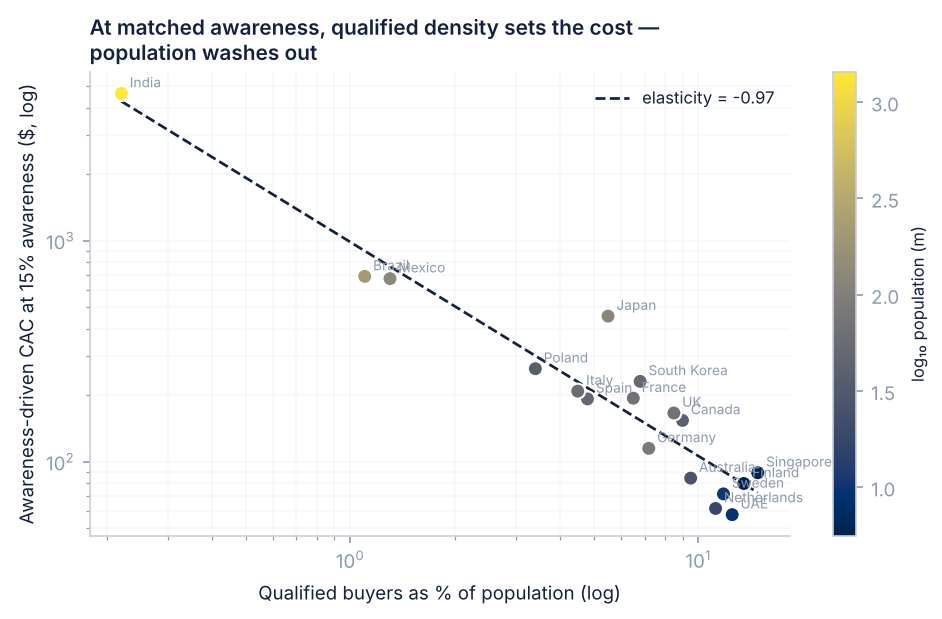

In [12]:
display(Image(f"{FIG}/f3_awareness_cac_vs_density.png"))

### Population washes out

Taken alone, log population correlates **+0.91** with awareness-driven CAC — which is
exactly the misleading result that would justify "avoid big markets."

Control for qualified density and media cost, and the population coefficient collapses
to **−0.11 (t = −0.66)**, indistinguishable from zero, in a regression explaining 95%
of the variance. What survives is:

- **qualified density −1.68** (t = −4.12)
- **media cost +1.81** (t = 2.55)

The algebra behind it is simple enough to say out loud in a meeting:

$$\text{CAC}_{\text{awareness}} \;\propto\; \frac{\overbrace{\text{pop} \times \text{cpm}}^{\text{cost of awareness}}}{\underbrace{\text{pop} \times \text{density} \times \gamma}_{\text{buyers it reaches}}} \;=\; \frac{\text{cpm}}{\text{density} \times \gamma}$$

**Population appears in both the numerator and the denominator and cancels.** Big
markets cost more to make aware *and* contain proportionally more buyers. The two
effects offset exactly.

What does not cancel is how *concentrated* the qualified buyers are. India is
expensive not because it is large but because 99.8% of the people your awareness
spend reaches cannot buy the product. Singapore is cheap not because it is small but
because roughly one person in seven is a plausible buyer.

**This reverses the planning heuristic.** "Enter small markets first" is wrong. The
rule is "enter dense markets first, at any size" — and it means a large, wealthy,
concentrated market is the best entry target available, not the scariest.

In [13]:
un = R["unreachable_markets"]
if un:
    print(f"Markets where {R['target_awareness']:.0%} awareness is unreachable "
          f"at 12x current brand budget:")
    for m in un:
        print(f"   {m['market']:12s} ceiling {m['max_feasible_awareness']:.1%}")
else:
    print("All markets can reach the target awareness level.")

All markets can reach the target awareness level.


A planning output rather than an academic one: in these markets, an awareness-led
strategy is not expensive — it is *unavailable* at any budget the business would
approve. They need a different playbook entirely (retail distribution, partnerships,
targeted performance against the thin qualified slice), not a bigger brand line.

## 6. Forecasting a market you have barely entered

The practical obstacle to all of this: a new country has a handful of months of data.
So I ran the test that actually matters. Mexico enters with **3 months** of history.
Fit three ways on the other 17 full markets plus those 3 months, then forecast
Mexico's next 10 months of CAC.

'                      approach activations MAPE CAC MAPE\n                    no pooling            34.0%    71.2%\n              complete pooling            15.5%    19.1%\npartial pooling (hierarchical)             7.8%     7.3%'

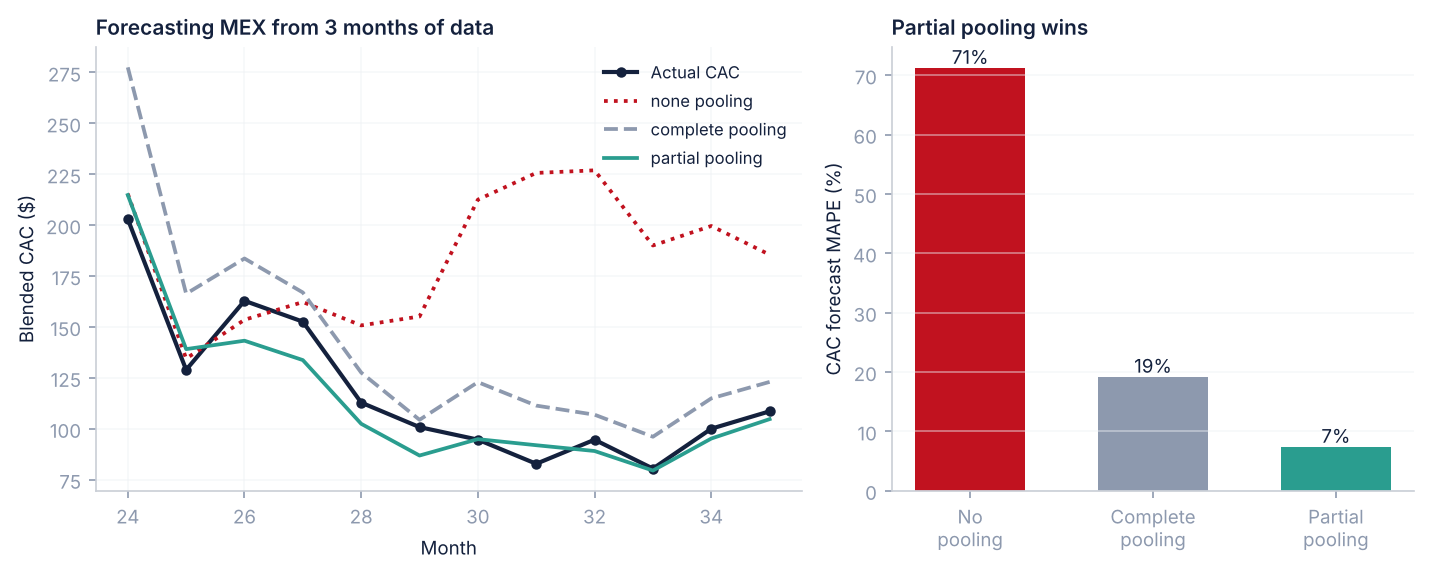

In [14]:
p = R["pooling"]
rows = [{"approach": k.replace("none","no pooling").replace("complete","complete pooling")
                      .replace("partial","partial pooling (hierarchical)"),
         "activations MAPE": f"{p[k]['activation_mape']:.1f}%",
         "CAC MAPE": f"{p[k]['cac_mape']:.1f}%"} for k in ["none","complete","partial"]]
display(pd.DataFrame(rows).to_string(index=False))
display(Image(f"{FIG}/f5_pooling_experiment.png"))

**71% → 19% → 7%.**

- *No pooling* fits Mexico on Mexico alone. Three observations, five parameters: the
  sampler threw 94 divergences and the forecast is unusable. This is what "let's wait
  until we have enough data" actually produces.
- *Complete pooling* applies one global coefficient set and does far better — but it
  insists Mexico behaves like Germany.
- *Partial pooling* shrinks Mexico's coefficients toward the group mean, weighted by
  how little data Mexico has, and beats both by a wide margin.

The shrinkage is a precision-weighted average:

$$E[\beta_c \mid \text{data}] \approx \frac{(n_c/\sigma^2)\hat\beta_c + (1/\tau^2)\mu}{(n_c/\sigma^2) + (1/\tau^2)}$$

A mature market with four years of data is trusted on its own evidence. A market with
three months is pulled toward the pooled mean. **Nobody chooses the weighting — τ is
estimated from the data**, so the model works out for itself how similar these markets
are.

This is the whole argument for hierarchical modelling in an expansion context, and it
is why I would build this as one model across all 56 markets rather than 56 models.

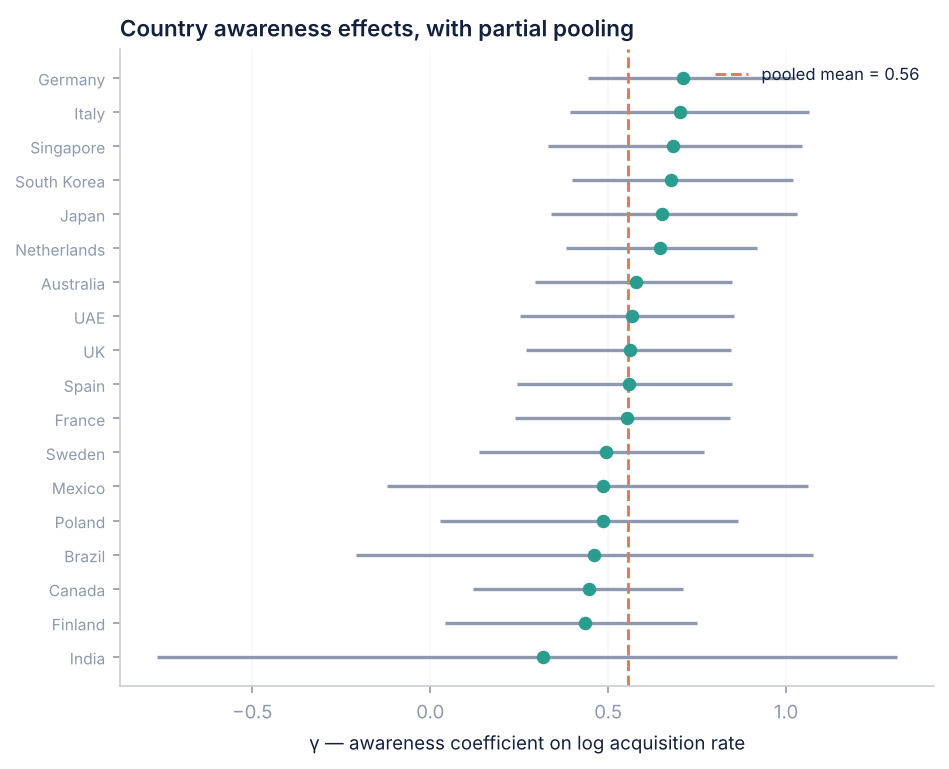

In [15]:
display(Image(f"{FIG}/f4_gamma_forest.png"))

Worth noting honestly: the per-country intervals are wide and heavily shrunk
(τ_γ = 0.18). The model is telling us it cannot distinguish country awareness effects
from observational data — consistent with the recovery failure in section 3. The
pooled mean is informative; the country deviations are not. A team that reported
per-country brand ROIs off this model would be reporting noise.

## 7. Decision layer

A coefficient is not a decision. Three outputs a planning team would actually use.

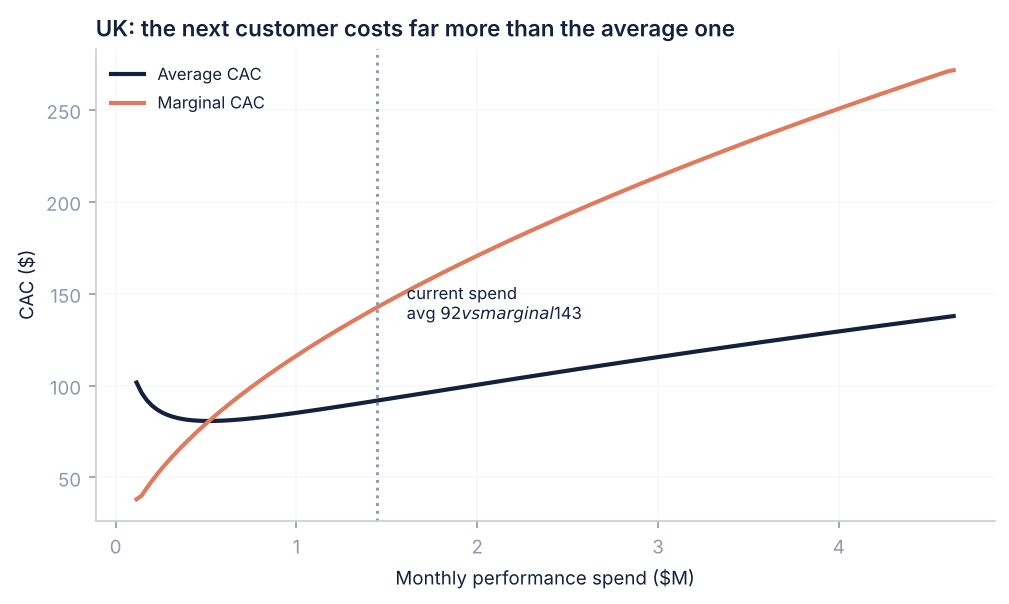

UK at current spend:  average CAC $92   marginal CAC $143   (1.6x)


In [16]:
display(Image(f"{FIG}/f6_marginal_vs_average_cac.png"))
gap = R["uk_cac_gap"]
print(f"UK at current spend:  average CAC ${gap['avg']:.0f}   "
      f"marginal CAC ${gap['marginal']:.0f}   ({gap['ratio']:.1f}x)")

**Average CAC is a reporting number; marginal CAC is the budgeting number.** For a
power-law response curve with exponent β, marginal CAC = average CAC ÷ β — so with
β ≈ 0.47, the next customer costs roughly twice the reported average. Teams that
budget off average CAC overspend systematically.

The allocation rule that follows: **set spend so marginal CAC is equal across all
channels and markets.** If the UK's marginal CAC is $180 and Spain's is $95, the next
dollar belongs in Spain, regardless of which has the better average.

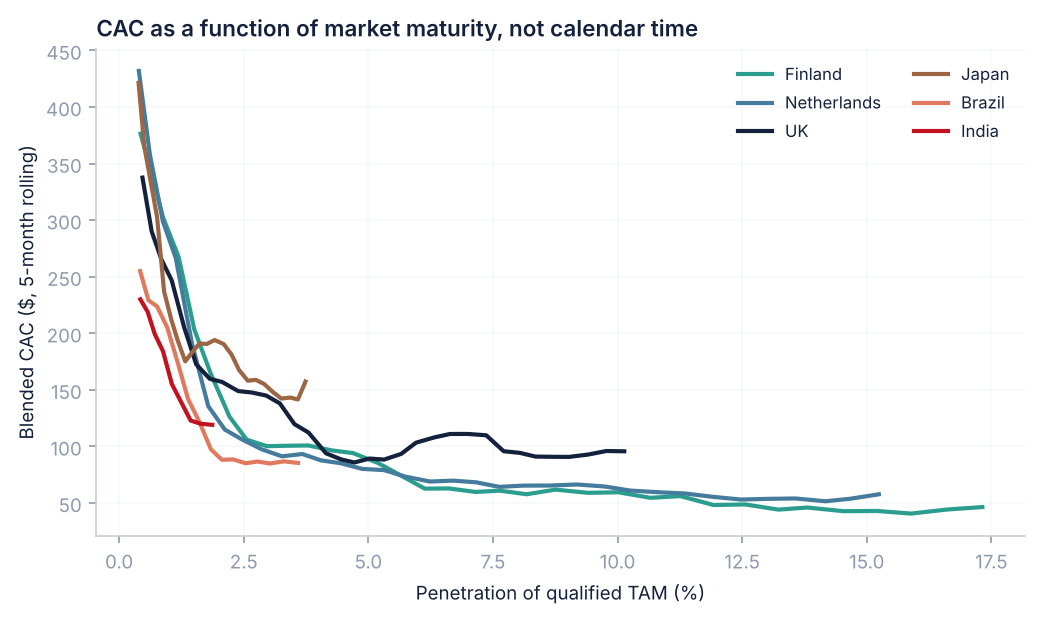

In [17]:
display(Image(f"{FIG}/f8_cac_vs_penetration.png"))

Plotting CAC against *penetration* rather than calendar time puts every market on a
comparable axis. A market 18 months old and a market 3 months old are not comparable;
two markets at 4% penetration are. This is the x-axis an entry planner needs.

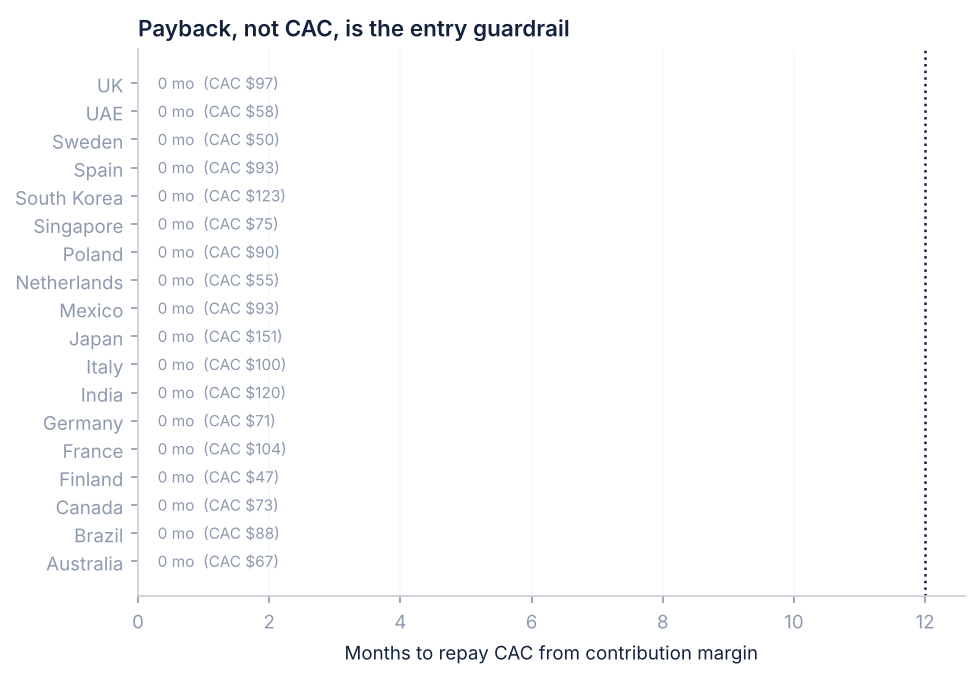

hardware contribution margin      $181
monthly subscription CM           $4.22
implied monthly retention         0.987


In [18]:
display(Image(f"{FIG}/f9_payback.png"))
e = R["unit_economics"]
print(f"hardware contribution margin      ${e['hardware_cm']:.0f}")
print(f"monthly subscription CM           ${e['monthly_subscription_cm']:.2f}")
print(f"implied monthly retention         {e['monthly_retention']:.3f}")

### CAC is the wrong guardrail

With hardware contribution margin around $180 and a subscription annuity behind it,
most of these markets repay acquisition cost immediately or within a few months. The
business can tolerate a much higher CAC than a pure-subscription company could.

So the entry guardrail should be **payback period on contribution margin**, not CAC.
A market with $250 CAC and strong retention is a better entry than one with $120 CAC
and churn. Optimising CAC directly would get that backwards.

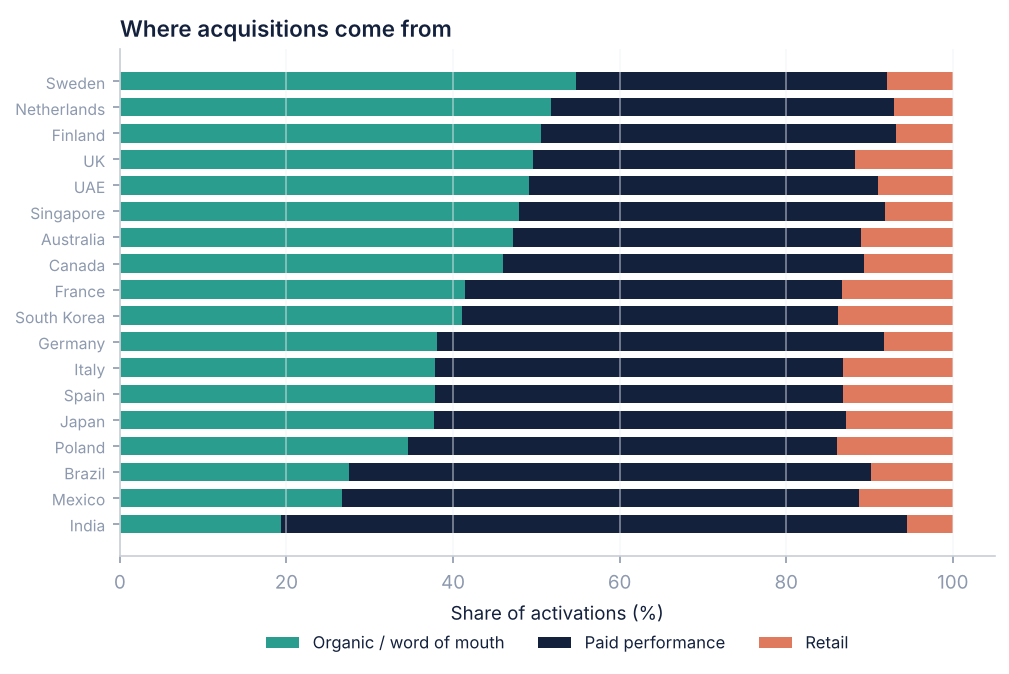

In [19]:
display(Image(f"{FIG}/f10_channel_mix.png"))

## 8. The measurement trap I would raise first

In a retail-heavy market, awareness drives sell-through that DTC attribution cannot
see. Brand spend goes up, retail units move, and **DTC CAC gets worse** — so the
reporting metric punishes the thing that is working.

Oura has an unusual escape from this. Every ring must be activated in the app to be
usable, so **app activation is a universal, geolocated acquisition event** across DTC,
Amazon and all ~8,400 retail doors. Most consumer hardware companies cannot measure
retail-driven acquisition at all; Oura can, with a lag.

Model activations, not orders. Everything in this notebook does.

In [20]:
dtc_gap = (panel.groupby("market")
           .apply(lambda g: pd.Series({
               "blended CAC": g.total_spend.sum()/g.activations.sum(),
               "DTC-only CAC": g.total_spend.sum()/(g.activations.sum()-g.retail_activations.sum()),
               "retail share": g.retail_activations.sum()/g.activations.sum()}),
                  include_groups=False)
           .sort_values("retail share", ascending=False))
dtc_gap["overstatement"] = (dtc_gap["DTC-only CAC"]/dtc_gap["blended CAC"]-1)
display(dtc_gap.head(8).round(3))
print(f"\nMeasuring CAC on DTC alone overstates it by "
      f"{dtc_gap.overstatement.mean():.0%} on average across markets.")

,blended CAC,DTC-only CAC,retail share,overstatement
market,,,,
Poland,126.226,146.548,0.139,0.161
South Korea,173.761,201.455,0.137,0.159
France,136.846,157.773,0.133,0.153
Italy,146.985,169.431,0.132,0.153
Spain,129.184,148.716,0.131,0.151
Japan,231.933,266.197,0.129,0.148
UK,133.666,151.422,0.117,0.133
Mexico,158.610,178.766,0.113,0.127



Measuring CAC on DTC alone overstates it by 12% on average across markets.


## 9. What I would do with this

**Build:** one hierarchical model across all 56 markets, not 56 models. Partial
pooling is what lets a market with one quarter of data get a usable forecast.

**Measure:** a standing geo-holdout programme on upper funnel, because the
observational model cannot see brand and is biased downward by ~69%. Pin the brand
coefficient to the experimental estimate rather than treating it as a prior.

**Report:** marginal CAC and payback period, on *activations* rather than DTC orders.
Average DTC CAC is the metric most likely to make good brand work look like failure.

**Select markets on qualified density, not size.** The planning heuristic "start small"
is wrong; the rule is "start dense."

### Limitations I would want on the record

- All data is simulated. The structural conclusions follow from the generative model,
  and a real dataset could behave differently — most plausibly if awareness effects do
  vary by market in ways my simulator holds constant.
- Carryover rates are grid-searched, not jointly estimated. Fully Bayesian treatment of
  θ would propagate that uncertainty properly.
- The "geo experiment" is simulated at a precision (se = 0.20) that a real test would
  need meaningful spend and several weeks to achieve.
- `qual_frac` is invented. In production it is a research deliverable, and the whole
  result is sensitive to it — which is itself a reason to invest in getting it right.

---

**Reproduce:** `python3 src/simulate.py && python3 src/analysis.py` (~4 minutes).
Code at [github.com/duanchenliu](https://github.com/duanchenliu).